# Adult Census Income: exploratory data analysis

**Dataset:** `adult-census/data/adult.csv` &nbsp;|&nbsp; **Notebook:** `adult-census/notebooks/01_eda.ipynb`

## 1. Introduction

The **Adult** dataset (a.k.a. "Census Income") was extracted by **Barry Becker** from the **1994 US Census Bureau** database and donated to the UCI Machine Learning Repository by **Ronny Kohavi and Barry Becker** in 1996. Extraction kept records with `age > 16`, `hours.per.week > 0`, a positive final weight, and adjusted gross income > 100 USD, so this is *not* a random sample of the US population.

**Task:** binary classification. Predict whether a person earns more than 50K USD a year (`income` in {`<=50K`, `>50K`}) from 14 demographic and employment attributes. This file is the 32,561-row "train" split.

**Why it is the canonical benchmark for tabular synthetic data:**
- **Mixed types.** It has 6 integer columns and 9 categorical ones, including ordinal and high-cardinality columns.
- **Hard marginals.** Several numerics are heavily zero-inflated, have spikes, or are multimodal.
- **Real dependencies.** It has a deterministic 1:1 mapping, near-deterministic logical rules, and strong conditional structure.
- **A downstream task.** There is a well-defined prediction task for *utility* metrics (train on synthetic, test on real).
- **Sensitive attributes.** `sex`, `race` and `native.country`, plus rare combinations, are relevant for *privacy* and *fairness* evaluation.
- Almost every generator paper uses it, including CTGAN/TVAE (Xu et al., 2019), PATE-GAN, PrivBayes, AIM, TabDDPM and ARF.

This notebook describes the data and ends with **concrete implications for the synthetic-data benchmark** (Section 10).

### Setup and helpers
These helpers are small and dataset-agnostic, so they can be copied to other `<dataset>/notebooks/01_eda.ipynb` notebooks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 90, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30, "display.width", 160, "display.precision", 3, "display.max_colwidth", 220)


def find_data_file(rel: str, start: Path | None = None) -> Path:
    """Walk up from `start` (default: cwd) until `rel` exists; return absolute path."""
    start = (start or Path.cwd()).resolve()
    for d in (start, *start.parents):
        if (d / rel).exists():
            return d / rel
    raise FileNotFoundError(f"{rel!r} not found above {start}")


def schema_table(df: pd.DataFrame, ordinal=frozenset(), missing_token=None, n_examples: int = 4) -> pd.DataFrame:
    """One row per column: semantic kind, dtype, cardinality, missing count, most frequent values."""
    rows = []
    for c in df.columns:
        s = df[c]
        kind = "ordinal" if c in ordinal else ("numeric" if pd.api.types.is_numeric_dtype(s) else "categorical")
        ex = s.value_counts().index[:n_examples].tolist()
        rows.append(dict(column=c, kind=kind, dtype=str(s.dtype), n_unique=s.nunique(),
                         n_missing=int(s.isna().sum() + (s == missing_token).sum()), top_values=", ".join(map(str, ex))))
    return pd.DataFrame(rows).set_index("column")


def numeric_profile(df: pd.DataFrame, cols) -> pd.DataFrame:
    """Summary statistics plus shape descriptors relevant for generative modelling."""
    out = {}
    for c in cols:
        s = df[c]
        mode = s.mode().iloc[0]
        out[c] = {"min": s.min(), "median": s.median(), "mean": s.mean(), "max": s.max(),
                  "n_unique": s.nunique(), "skew": stats.skew(s), "excess_kurtosis": stats.kurtosis(s),
                  "share_zero": (s == 0).mean(), "mode": mode, "share_mode": (s == mode).mean(),
                  "share_max": (s == s.max()).mean()}
    return pd.DataFrame(out).T


def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Bias-corrected Cramer's V (Bergsma, 2013) between two categorical series."""
    ct = pd.crosstab(x, y)
    if min(ct.shape) < 2:
        return 0.0
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_, k_ = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(k_ - 1, r_ - 1))))


def cramers_v_matrix(df: pd.DataFrame, cols) -> pd.DataFrame:
    m = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            m.loc[a, b] = m.loc[b, a] = cramers_v(df[a], df[b])
    return m


def rate_by(df: pd.DataFrame, col: str, target: pd.Series) -> pd.DataFrame:
    """Positive-class rate and count per level of `col`, sorted by rate."""
    g = target.groupby(df[col], observed=True)
    return pd.DataFrame({"n": g.size(), "rate": g.mean()}).sort_values("rate", ascending=False)

In [2]:
DATA_PATH = find_data_file("adult-census/data/adult.csv")
MISSING_TOKEN = "?"
TARGET, POSITIVE = "income", ">50K"

raw = pd.read_csv(DATA_PATH)                                   # keep "?" as a literal category
df = pd.read_csv(DATA_PATH, na_values=[MISSING_TOKEN])        # "?" -> NaN, for missingness analysis
y = (df[TARGET] == POSITIVE).astype(int)

NUMERIC = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
CATEGORICAL = [c for c in df.columns if c not in NUMERIC]
ORDINAL = {"education", "education.num"}
print(f"{DATA_PATH.relative_to(DATA_PATH.parents[2])}: {df.shape[0]:,} rows x {df.shape[1]} columns")
raw.head()

adult-census/data/adult.csv: 32,561 rows x 15 columns


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## 2. Schema and dtypes

Here `kind` is the *semantic* type, which matters for generators that treat each type differently. `education` and `education.num` encode the same ordinal variable (see Section 8). In the generator's input both are passed as-is, as a categorical and an integer.

In [3]:
schema_table(raw, ordinal=ORDINAL, missing_token=MISSING_TOKEN)  # n_unique counts '?' as a level

,kind,dtype,n_unique,n_missing,top_values
column,,,,,
age,numeric,int64,73,0,"36, 31, 34, 23"
workclass,categorical,object,9,1836,"Private, Self-emp-not-inc, Local-gov, ?"
fnlwgt,numeric,int64,21648,0,"203488, 123011, 164190, 121124"
education,ordinal,object,16,0,"HS-grad, Some-college, Bachelors, Masters"
education.num,ordinal,int64,16,0,"9, 10, 13, 14"
marital.status,categorical,object,7,0,"Married-civ-spouse, Never-married, Divorced, Separated"
occupation,categorical,object,15,1843,"Prof-specialty, Craft-repair, Exec-managerial, Adm-clerical"
relationship,categorical,object,6,0,"Husband, Not-in-family, Own-child, Unmarried"
race,categorical,object,5,0,"White, Black, Asian-Pac-Islander, Amer-Indian-Eskimo"


- **6 integer columns.** `age` (73 distinct values) and `fnlwgt` (21,648) are effectively continuous. `education.num` (16) is ordinal. `capital.gain` (119), `capital.loss` (92) and `hours.per.week` (94) are discrete with spikes.
- **9 categorical columns.** Cardinality runs from 2 (`sex`, `income`) to 41 countries plus missing (`native.country`). There are no free-text or date columns.
- Every column is stored as an integer or a string. **No numeric column has fractional values**, so a generator should round its numeric output, or a fidelity check should allow for that.

## 3. Missingness
Missing values are encoded as the literal string `"?"`. They appear in only three categorical columns.

In [4]:
miss = df.isna()
miss_tbl = pd.DataFrame({"n_missing": miss.sum(), "pct": 100 * miss.mean()}).query("n_missing > 0")
print(f"rows with any missing value: {miss.any(axis=1).sum():,} ({100 * miss.any(axis=1).mean():.1f}%)")
miss_tbl

rows with any missing value: 2,399 (7.4%)


,n_missing,pct
workclass,1836,5.639
occupation,1843,5.660
native.country,583,1.790


In [5]:
print("Co-occurrence of missing workclass (rows) x missing occupation (columns):")
display(pd.crosstab(miss["workclass"], miss["occupation"], margins=True))
print("workclass for rows where occupation is missing:")
display(raw.loc[miss["occupation"], "workclass"].value_counts().to_frame())

Co-occurrence of missing workclass (rows) x missing occupation (columns):


occupation,False,True,All
workclass,,,
False,30718,7,30725
True,0,1836,1836
All,30718,1843,32561


workclass for rows where occupation is missing:


,count
workclass,
?,1836
Never-worked,7


In [6]:
grp = {"occupation missing": miss["occupation"], "workclass missing": miss["workclass"],
       "native.country missing": miss["native.country"], "no missing value": ~miss.any(axis=1),
       "all rows": pd.Series(True, index=df.index)}
pd.DataFrame({k: {"n": int(m.sum()), "P(>50K)": y[m].mean(),
                  "median age": df.loc[m, "age"].median(), "share age<25": (df.loc[m, "age"] < 25).mean(),
                  "share age>=60": (df.loc[m, "age"] >= 60).mean(),
                  "median hours": df.loc[m, "hours.per.week"].median()} for k, m in grp.items()}).T

,n,P(>50K),median age,share age<25,share age>=60,median hours
occupation missing,1843.0,0.104,35.0,0.346,0.284,36.0
workclass missing,1836.0,0.104,35.0,0.344,0.285,36.0
native.country missing,583.0,0.250,37.0,0.117,0.072,40.0
no missing value,30162.0,0.249,37.0,0.161,0.069,40.0
all rows,32561.0,0.241,37.0,0.171,0.081,40.0


**Findings**
- `workclass` has 1,836 missing values (5.6%), `occupation` 1,843 (5.7%) and `native.country` 583 (1.8%). In total 2,399 rows (7.4%) have at least one missing value.
- **Missing `workclass` always implies missing `occupation`**, with no exceptions. The 7 extra rows with missing occupation are exactly the `workclass = Never-worked` rows, which is a *structural* missingness: someone who never worked has no occupation. This is a **logical rule a generator should keep**: `workclass == "?"` implies `occupation == "?"`.
- The missingness is **not at random**. Only about 10% of rows with missing occupation earn >50K, against about 24% overall. Their median age (35) is close to the overall median (37), but the group is **bimodal**: 35% are under 25 and 28% are 60 or older, against 16% and 7% for rows without missing occupation. That pattern fits students and retirees outside the regular labour force, and the group also works fewer hours (median 36 vs 40). Missing `native.country` shows no such shift (25.0% `>50K`).
- Implication: treat `"?"` as an **informative category of its own** rather than dropping or imputing it.

## 4. Target: class balance

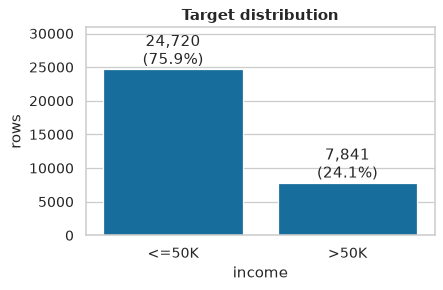

In [7]:
counts = df[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(5, 3))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(ylabel="rows", xlabel=TARGET, title="Target distribution", ylim=(0, counts.max() * 1.25))
plt.show()

The target is **imbalanced at about 3:1**: 24,720 rows (75.9%) are `<=50K` and 7,841 (24.1%) are `>50K`. A majority-class classifier already reaches 75.9% accuracy, so utility evaluation (TSTR) should report **ROC-AUC / F1 / balanced accuracy** rather than accuracy alone. Generators also tend to under-produce the minority class, so the synthetic `>50K` share should be checked directly.

## 5. Numeric univariates

In [8]:
numeric_profile(df, NUMERIC)

,min,median,mean,max,n_unique,skew,excess_kurtosis,share_zero,mode,share_mode,share_max
age,17.0,37.0,38.582,9.000e+01,73.0,0.559,-0.166,0.000,36.0,2.758e-02,1.321e-03
fnlwgt,12285.0,178356.0,189778.367,1.485e+06,21648.0,1.447,6.218,0.000,123011.0,3.993e-04,3.071e-05
education.num,1.0,10.0,10.081,1.600e+01,16.0,-0.312,0.623,0.000,9.0,3.225e-01,1.268e-02
capital.gain,0.0,0.0,1077.649,1.000e+05,119.0,11.953,154.775,0.917,0.0,9.167e-01,4.883e-03
capital.loss,0.0,0.0,87.304,4.356e+03,92.0,4.594,20.373,0.953,0.0,9.533e-01,9.213e-05
hours.per.week,1.0,40.0,40.437,9.900e+01,94.0,0.228,2.916,0.000,40.0,4.673e-01,2.610e-03


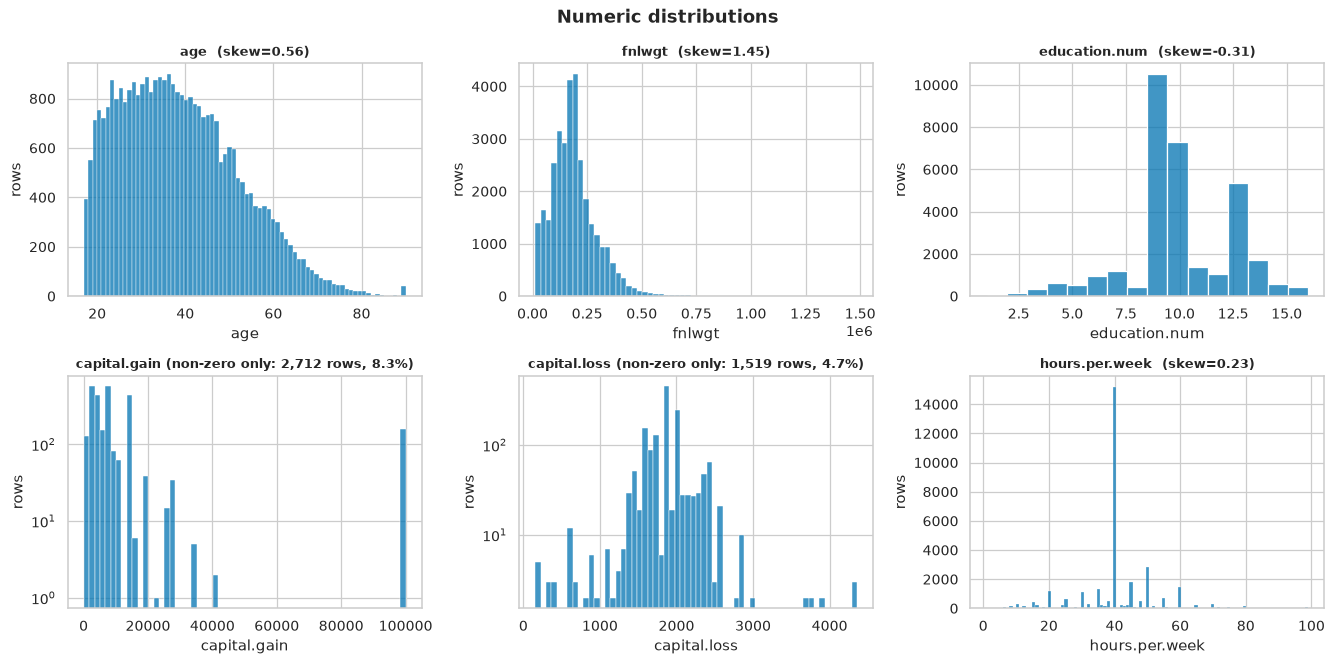

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.flat, NUMERIC):
    s = df[c]
    if c in ("capital.gain", "capital.loss"):
        nz = s[s > 0]
        sns.histplot(nz, bins=60, ax=ax)
        ax.set_title(f"{c} (non-zero only: {len(nz):,} rows, {len(nz) / len(s):.1%})", fontsize=10)
        ax.set_yscale("log")
    else:
        sns.histplot(s, bins=int(s.max() - s.min() + 1) if s.nunique() < 100 else 60, ax=ax)
        ax.set_title(f"{c}  (skew={stats.skew(s):.2f})", fontsize=10)
    ax.set_ylabel("rows")
fig.suptitle("Numeric distributions", fontsize=14, weight="bold")
fig.tight_layout()
plt.show()

In [10]:
print("Most frequent values (share of rows):")
for c in ["hours.per.week", "capital.gain", "capital.loss", "age"]:
    top = df[c].value_counts(normalize=True).head(5)
    print(f"  {c:15s}", ", ".join(f"{k}: {v:.1%}" for k, v in top.items()))
print()
print(f"capital.gain == 99999 (top-coded): {(df['capital.gain'] == 99999).sum()} rows, "
      f"P(>50K) = {y[df['capital.gain'] == 99999].mean():.0%}")
print(f"age == 90 (top-coded): {(df['age'] == 90).sum()} rows;  hours.per.week == 99: {(df['hours.per.week'] == 99).sum()} rows")
print(f"rows with BOTH capital.gain > 0 and capital.loss > 0: {((df['capital.gain'] > 0) & (df['capital.loss'] > 0)).sum()}")

Most frequent values (share of rows):
  hours.per.week  40: 46.7%, 50: 8.7%, 45: 5.6%, 60: 4.5%, 35: 4.0%
  capital.gain    0: 91.7%, 15024: 1.1%, 7688: 0.9%, 7298: 0.8%, 99999: 0.5%
  capital.loss    0: 95.3%, 1902: 0.6%, 1977: 0.5%, 1887: 0.5%, 1848: 0.2%
  age             36: 2.8%, 31: 2.7%, 34: 2.7%, 23: 2.7%, 35: 2.7%

capital.gain == 99999 (top-coded): 159 rows, P(>50K) = 100%
age == 90 (top-coded): 43 rows;  hours.per.week == 99: 85 rows
rows with BOTH capital.gain > 0 and capital.loss > 0: 0


**Findings**
- **`age`** ranges from 17 to 90 and is right-skewed (skew 0.56). There is a small pile-up at 90 (43 rows), which is probably top-coding.
- **`fnlwgt`** ranges from 12,285 to 1,484,705 and has a long right tail (skew 1.45, excess kurtosis 6.2). A log10 transform reduces the skew but overshoots, giving a left skew of -0.84 (§8.3).
- **`education.num`** takes 16 integer levels and is dominated by 9 (HS-grad, 32%), 10 (Some-college) and 13 (Bachelors).
- **`hours.per.week` has a strong spike at 40**: 46.7% of all rows have exactly 40. There are secondary spikes at 50, 45, 60, 35 and 20, and 85 rows at the cap of 99. It is a mixture of point masses, not a smooth density.
- **`capital.gain` is 91.7% zeros** (skew 11.9, kurtosis 155). The non-zero part takes only 118 distinct values, and **159 rows sit at the 99999 top-code**, all of them `>50K`.
- **`capital.loss` is 95.3% zeros**, with a narrow non-zero cluster around 1,500 to 2,500.
- **`capital.gain` and `capital.loss` are never both non-zero** (0 rows), so they are mutually exclusive. This is another logical rule to check in synthetic data.

## 6. Categorical univariates

In [11]:
cat_card = pd.DataFrame({
    "n_levels": raw[CATEGORICAL].nunique(),
    "top_level": raw[CATEGORICAL].apply(lambda s: s.value_counts().index[0]),
    "top_share": raw[CATEGORICAL].apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "n_levels_lt30": raw[CATEGORICAL].apply(lambda s: int((s.value_counts() < 30).sum())),
    "rows_in_levels_lt30": raw[CATEGORICAL].apply(lambda s: int(s.value_counts()[lambda v: v < 30].sum())),
}).sort_values("n_levels", ascending=False)
cat_card

,n_levels,top_level,top_share,n_levels_lt30,rows_in_levels_lt30
native.country,42,United-States,0.896,15,273
education,16,HS-grad,0.323,0,0
occupation,15,Prof-specialty,0.127,1,9
workclass,9,Private,0.697,2,21
marital.status,7,Married-civ-spouse,0.460,1,23
relationship,6,Husband,0.405,0,0
race,5,White,0.854,0,0
sex,2,Male,0.669,0,0
income,2,<=50K,0.759,0,0


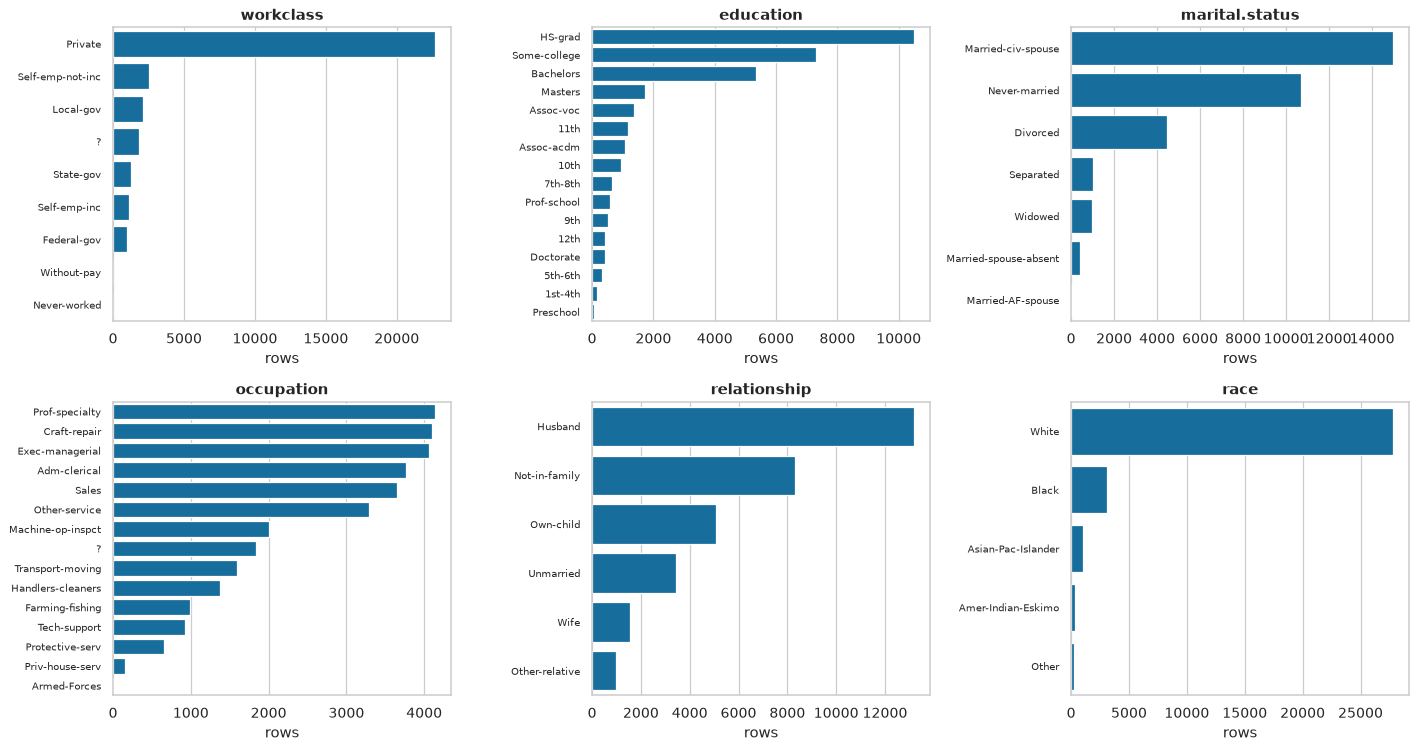

In [12]:
plot_cols = ["workclass", "education", "marital.status", "occupation", "relationship", "race"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, c in zip(axes.flat, plot_cols):
    vc = raw[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color=sns.color_palette()[0])
    ax.set(title=c, xlabel="rows", ylabel="")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

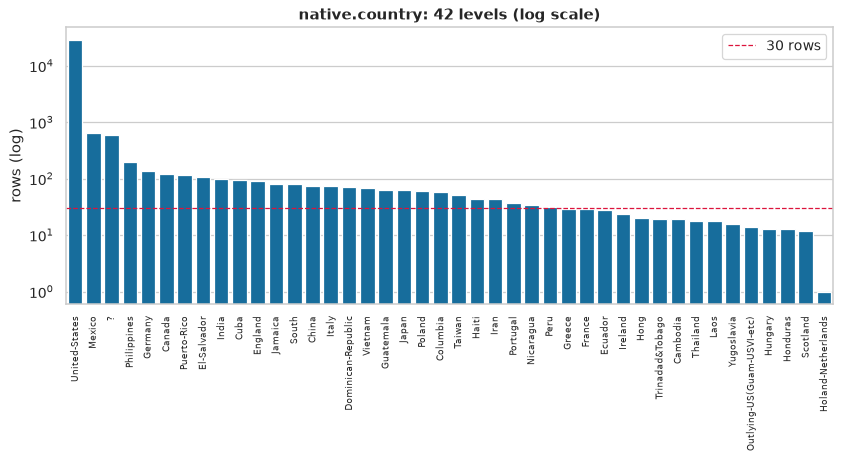

United-States share: 89.6%;  next: Mexico 643, ? 583, Philippines 198


In [13]:
vc = raw["native.country"].value_counts()
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=vc.index, y=vc.values, ax=ax, color=sns.color_palette()[0])
ax.set_yscale("log"); ax.axhline(30, ls="--", c="crimson", lw=1, label="30 rows")
ax.set(title=f"native.country: {vc.size} levels (log scale)", ylabel="rows (log)", xlabel="")
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.legend()
plt.show()
print(f"United-States share: {vc.iloc[0] / vc.sum():.1%};  next: " + ", ".join(f"{k} {v}" for k, v in vc.iloc[1:4].items()))

In [14]:
rare = (raw[CATEGORICAL].melt(var_name="column", value_name="level")
        .value_counts().rename("n").reset_index().query("n < 30").sort_values(["column", "n"]))
print(f"{len(rare)} rare (count < 30) category levels across {rare['column'].nunique()} columns:")
rare.assign(level=lambda d: d["level"] + " (" + d["n"].astype(str) + ")").groupby("column")["level"] \
    .apply(", ".join).to_frame("levels with < 30 rows")

19 rare (count < 30) category levels across 4 columns:


,levels with < 30 rows
column,
marital.status,Married-AF-spouse (23)
native.country,"Holand-Netherlands (1), Scotland (12), Honduras (13), Hungary (13), Outlying-US(Guam-USVI-etc) (14), Yugoslavia (16), Laos (18), Thailand (18), Trinadad&Tobago (19), Cambodia (19), Hong (20), Ireland (24), Ecuador (2..."
occupation,Armed-Forces (9)
workclass,"Never-worked (7), Without-pay (14)"


**Findings**
- **`native.country` has 42 levels**: 41 countries plus `?`. **United-States accounts for 89.6%** of rows, followed by Mexico (2.0%) and `?` (1.8%). The long tail has **15 countries with fewer than 30 rows**, down to `Holand-Netherlands` with a single row.
- Other rare levels: `workclass` has `Without-pay` (14) and `Never-worked` (7), `marital.status` has `Married-AF-spouse` (23), and `occupation` has `Armed-Forces` (9).
- `race` is dominated by `White` (85%) and `sex` is about 2:1 Male to Female. Both are imbalanced sensitive attributes, so the per-group fidelity of synthetic data deserves its own check.
- Rare levels are both **hard to learn** (a generator may never sample them, or may invent implausible combinations) and a **privacy risk**: a single Dutch-born record is almost a unique identifier, and if a synthetic sample reproduces it, that leaks information.

## 7. Bivariate structure
### 7.1 Numeric-numeric (Spearman)

Spearman with target: {'education.num': 0.33, 'capital.gain': 0.278, 'age': 0.273, 'hours.per.week': 0.269, 'capital.loss': 0.141, 'fnlwgt': -0.011}


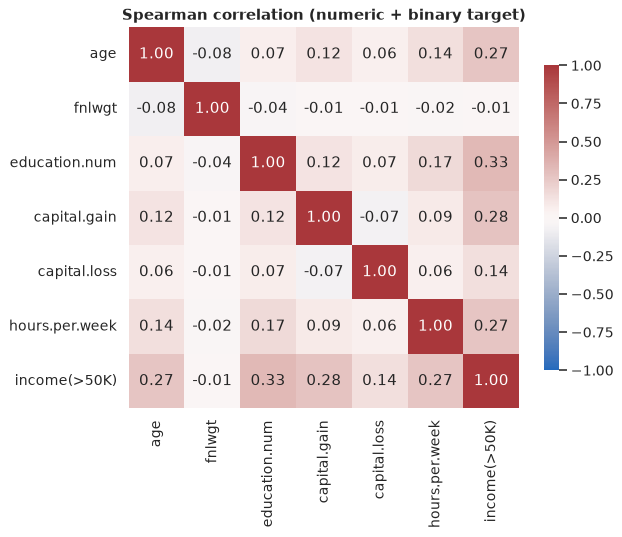

In [15]:
sp = df[NUMERIC].assign(**{"income(>50K)": y}).corr("spearman")
print("Spearman with target:", sp["income(>50K)"].drop("income(>50K)").sort_values(ascending=False).round(3).to_dict())
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(sp, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Spearman correlation (numeric + binary target)")
plt.show()

The numeric columns are **only weakly correlated with each other**: every pairwise |ρ| ≤ 0.17, the largest being `education.num` with `hours.per.week` (0.17), then `age` with `hours.per.week` (0.14). The useful signal is their relation to the **target**: `education.num` (0.33), `capital.gain` (0.28), `age` (0.27), `hours.per.week` (0.27) and `capital.loss` (0.14). **`fnlwgt` has none** (-0.01). Linear or rank correlations understate the structure, though: age has an inverted-U relation with income (§7.4), and capital.gain works mostly as a threshold effect.

### 7.2 Categorical association (bias-corrected Cramér's V, incl. target)

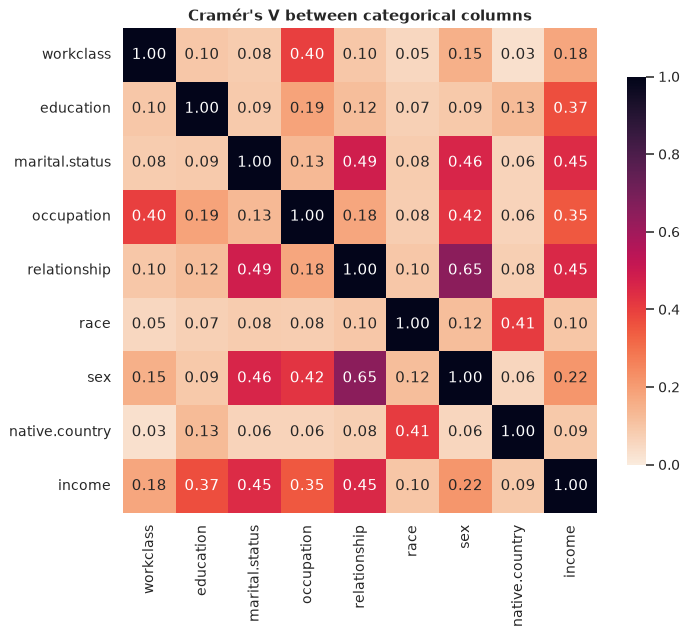

Strongest pairs:
relationship    sex               0.649
marital.status  relationship      0.488
                sex               0.462
relationship    income            0.453
marital.status  income            0.447
occupation      sex               0.424
race            native.country    0.408
workclass       occupation        0.400

Association with income:
relationship      0.453
marital.status    0.447
education         0.368
occupation        0.351
sex               0.216
workclass         0.179
race              0.100
native.country    0.092


In [16]:
cv = cramers_v_matrix(raw, CATEGORICAL)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Cramér's V between categorical columns")
plt.show()
print("Strongest pairs:")
pairs = cv.where(np.triu(np.ones(cv.shape, bool), 1)).stack().sort_values(ascending=False)
print(pairs.head(8).round(3).to_string())
print("\nAssociation with income:")
print(cv[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

- The strongest categorical association is **`relationship` with `sex`** (V = 0.65), which is the Husband/Wife coding (§8.2). Next come `marital.status` with `relationship` (0.49) and with `sex` (0.46).
- `occupation` with `sex` (0.42) shows strong occupational gender segregation. `race` with `native.country` (0.41) and `workclass` with `occupation` (0.40) are boosted partly by the shared `?` category.
- **Income** is most associated with `relationship` (0.45) and `marital.status` (0.45), then `education` (0.37) and `occupation` (0.35). It is weakly associated with `sex` (0.22) and `workclass` (0.18), and barely with `race` (0.10) or `native.country` (0.09).
- For synthesis, these association matrices are a compact **pairwise-fidelity target**: comparing real and synthetic Cramér's V matrices directly shows whether a generator kept the dependency structure.

### 7.3 Income rate by group

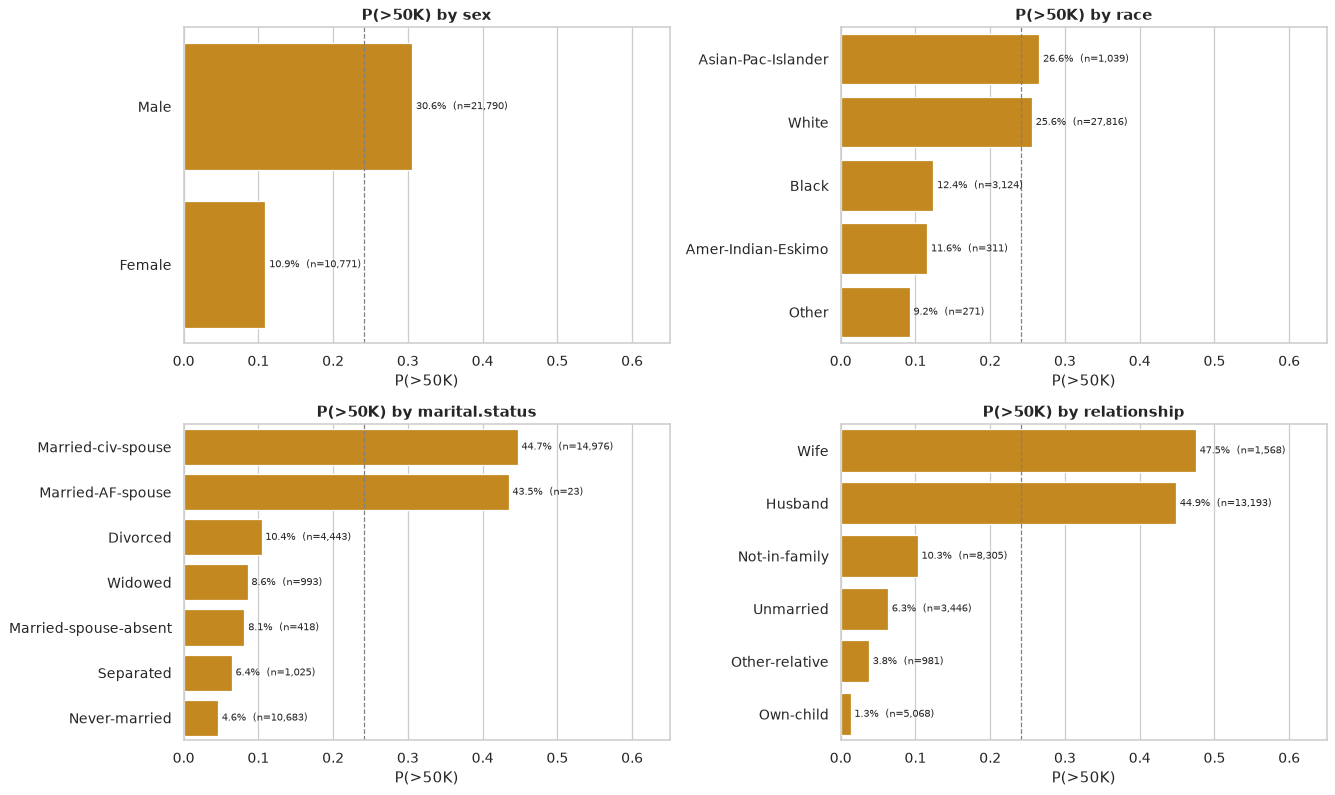

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, c in zip(axes.flat, ["sex", "race", "marital.status", "relationship"]):
    r = rate_by(raw, c, y)
    sns.barplot(x=r["rate"], y=r.index, ax=ax, color=sns.color_palette()[1])
    for i, (n, rate) in enumerate(zip(r["n"], r["rate"])):
        ax.text(rate + 0.005, i, f"{rate:.1%}  (n={n:,})", va="center", fontsize=8)
    ax.axvline(y.mean(), ls="--", c="grey", lw=1)
    ax.set(title=f"P(>50K) by {c}", xlabel="P(>50K)", ylabel="", xlim=(0, 0.65))
fig.tight_layout()
plt.show()

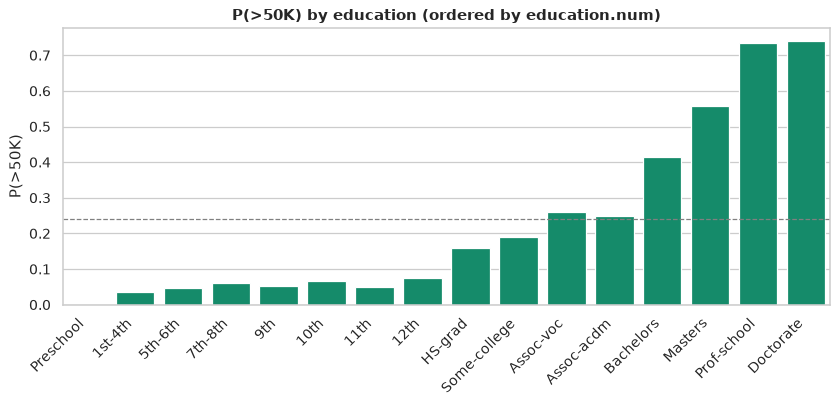

In [18]:
edu = (raw.groupby(["education.num", "education"]).size().rename("n").reset_index()
       .merge(y.groupby(raw["education.num"]).mean().rename("rate"), left_on="education.num", right_index=True))
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=edu, x="education", y="rate", ax=ax, color=sns.color_palette()[2])
ax.axhline(y.mean(), ls="--", c="grey", lw=1)
ax.set(title="P(>50K) by education (ordered by education.num)", ylabel="P(>50K)", xlabel="")
ax.tick_params(axis="x", rotation=45)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")
plt.show()

- **Sex:** 30.6% of men earn >50K against 10.9% of women.
- **Race:** `White` (25.6%) and `Asian-Pac-Islander` (26.6%) are well above `Black` (12.4%), `Amer-Indian-Eskimo` (11.6%) and `Other` (9.2%). The last three are small groups, so their rates are noisy, which matters for fairness metrics on synthetic data.
- **Marital status / relationship:** this is the strongest categorical driver. `Married-civ-spouse` has a 44.7% rate (`Married-AF-spouse` 43.5%, but n = 23) (and `Husband` 44.9%, `Wife` 47.5%), while `Never-married` has 4.6% and `Own-child` 1.3%.
- **Education:** the rate rises monotonically in steps, from about 0% (Preschool) and under 8% (anything below HS-grad) to 16% (HS-grad), 41.5% (Bachelors), 55.7% (Masters), and about 74% (Prof-school and Doctorate).

### 7.4 Age vs income

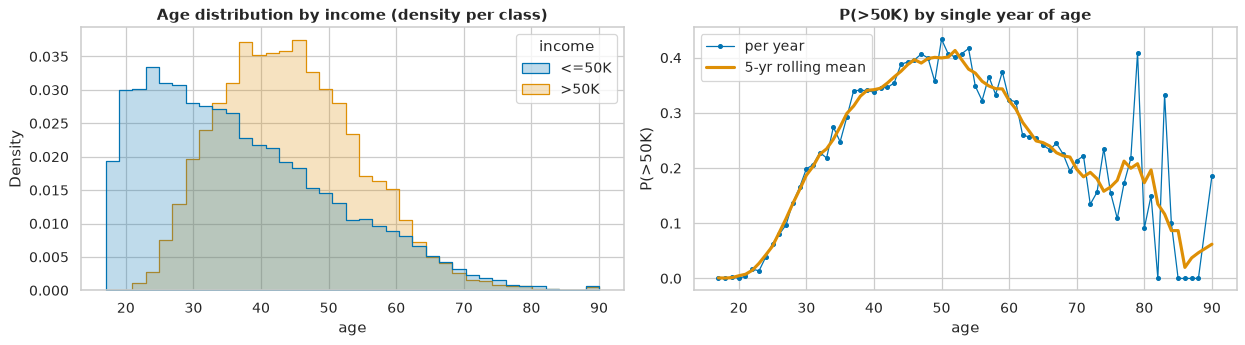

median age: <=50K = 34, >50K = 44; peak P(>50K) at age 50 (43.4%, among ages with n>=100)


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=raw, x="age", hue=TARGET, bins=37, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Age distribution by income (density per class)")
age_rate = y.groupby(df["age"]).mean()
age_n = df["age"].value_counts().sort_index()
axes[1].plot(age_rate.index, age_rate.values, marker=".", lw=1, label="per year")
axes[1].plot(age_rate.index, age_rate.rolling(5, center=True, min_periods=1).mean(), lw=2.5, label="5-yr rolling mean")
axes[1].set(title="P(>50K) by single year of age", xlabel="age", ylabel="P(>50K)")
axes[1].legend()
fig.tight_layout()
plt.show()
print(f"median age: <=50K = {df.loc[y == 0, 'age'].median():.0f}, >50K = {df.loc[y == 1, 'age'].median():.0f}; "
      f"peak P(>50K) at age {age_rate[age_n >= 100].idxmax()} ({age_rate[age_n >= 100].max():.1%}, among ages with n>=100)")

Age has a **non-monotonic (inverted-U) relationship** with income. Almost nobody under 25 earns >50K (about 2% for ages 17 to 25). Among ages with at least 100 rows, the rate peaks at **age 50 (43.4%)**, then declines after the mid-50s. The median age is **34 for `<=50K` and 44 for `>50K`**. A generator has to capture this *conditional* shape, not just the age marginal; a model that keeps only linear correlations will get it wrong.

## 8. Redundancies and semantics
### 8.1 `education` ↔ `education.num`

In [20]:
m1 = raw.groupby("education")["education.num"].nunique().max()
m2 = raw.groupby("education.num")["education"].nunique().max()
print(f"max distinct education.num per education level: {m1};  max distinct education per education.num: {m2}")
print("=> exact 1:1 (bijective) mapping" if m1 == m2 == 1 else "=> NOT 1:1")
raw.groupby(["education.num", "education"]).size().rename("n").reset_index().set_index("education.num").T

max distinct education.num per education level: 1;  max distinct education per education.num: 1
=> exact 1:1 (bijective) mapping


education.num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
n,51,168,333,646,514,933,1175,433,10501,7291,1382,1067,5355,1723,576,413


The mapping is an **exact bijection over 16 levels**: `education.num` is just the ordinal rank of `education`, from 1 = Preschool to 16 = Doctorate. The two columns carry the same information. A generator that models them independently can produce **inconsistent pairs** (for example `Bachelors` with `education.num = 9`). Real data has none.

### 8.2 `relationship` ↔ `sex` / `marital.status`

In [21]:
display(pd.crosstab(raw["relationship"], raw["sex"]))
display(pd.crosstab(raw["relationship"], raw["marital.status"]))

sex,Female,Male
relationship,,
Husband,1,13192
Not-in-family,3875,4430
Other-relative,430,551
Own-child,2245,2823
Unmarried,2654,792
Wife,1566,2


marital.status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,9,13184,0,0,0,0
Not-in-family,2404,0,17,211,4706,420,547
Other-relative,110,1,124,32,611,55,48
Own-child,328,1,95,45,4485,99,15
Unmarried,1601,0,0,130,881,451,383
Wife,0,12,1556,0,0,0,0


In [22]:
married = raw["marital.status"].isin(["Married-civ-spouse", "Married-AF-spouse"])
RULES = {  # name -> boolean mask of VIOLATING rows; reusable as a constraint check on synthetic data
    "education <-> education.num consistent": raw["education.num"] != raw["education"].map(
        raw.groupby("education")["education.num"].first()),
    "Husband => Male":                   (raw["relationship"] == "Husband") & (raw["sex"] != "Male"),
    "Wife => Female":                    (raw["relationship"] == "Wife") & (raw["sex"] != "Female"),
    "Husband/Wife => married (civ/AF)":  raw["relationship"].isin(["Husband", "Wife"]) & ~married,
    "Unmarried => not married (civ/AF)": (raw["relationship"] == "Unmarried") & married,
    "workclass '?' => occupation '?'":   (raw["workclass"] == "?") & (raw["occupation"] != "?"),
    "Never-worked => occupation '?'":    (raw["workclass"] == "Never-worked") & (raw["occupation"] != "?"),
    "not (capital.gain>0 and capital.loss>0)": (raw["capital.gain"] > 0) & (raw["capital.loss"] > 0),
    "capital.gain == 99999 => >50K":     (raw["capital.gain"] == 99999) & (raw[TARGET] != POSITIVE),
}
pd.DataFrame({"violations": {k: int(v.sum()) for k, v in RULES.items()},
              "violation_rate": {k: v.mean() for k, v in RULES.items()}})

,violations,violation_rate
education <-> education.num consistent,0,0.000e+00
Husband => Male,1,3.071e-05
Wife => Female,2,6.142e-05
Husband/Wife => married (civ/AF),0,0.000e+00
Unmarried => not married (civ/AF),0,0.000e+00
workclass '?' => occupation '?',0,0.000e+00
Never-worked => occupation '?',0,0.000e+00
not (capital.gain>0 and capital.loss>0),0,0.000e+00
capital.gain == 99999 => >50K,0,0.000e+00


- `relationship` is **strongly coupled** with `sex` and `marital.status`. `Husband` is Male in 13,192 of 13,193 rows and `Wife` is Female in 1,566 of 1,568, so the real data has **3 violations in total** (1 + 2), probably coding errors. "Husband ⇒ Male" is therefore a *near*-deterministic rule (99.98%), not a strict one.
- `Husband`/`Wife` occur **only** with `Married-civ-spouse` or `Married-AF-spouse`, and `Unmarried` never does. Both rules hold with zero violations.
- These rules are good **logical-consistency checks** for synthetic data. In the real data the violation rate is 0, or at most 0.006% of rows. A good generator should be close to that, while a generator that treats columns as nearly independent (for example `marginal_distributions`) will violate them often.

### 8.3 `fnlwgt`: a sampling weight, not a personal attribute

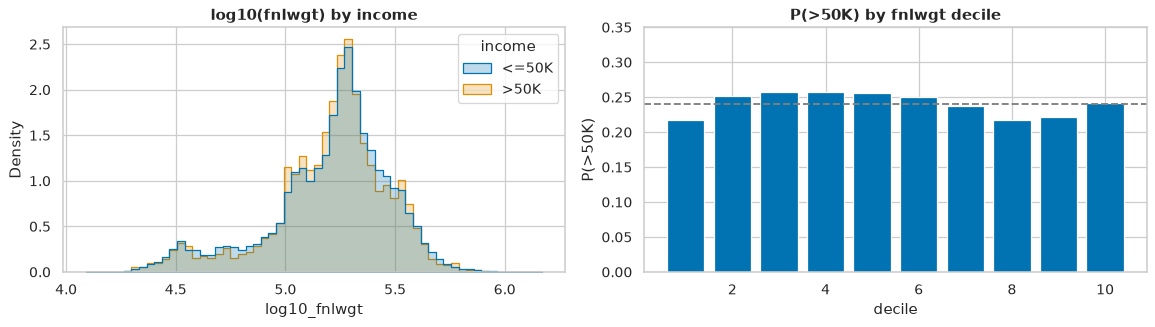

Spearman(fnlwgt, >50K) = -0.0107 (p = 0.053);  P(>50K) across deciles: 0.217 to 0.258
skew of log10(fnlwgt): -0.84;  share of unique fnlwgt values: 66.5%


In [23]:
rho, p = stats.spearmanr(df["fnlwgt"], y)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(data=raw.assign(log10_fnlwgt=np.log10(raw["fnlwgt"])), x="log10_fnlwgt", hue=TARGET,
             stat="density", common_norm=False, bins=60, element="step", ax=axes[0])
axes[0].set_title("log10(fnlwgt) by income")
dec = y.groupby(pd.qcut(df["fnlwgt"], 10), observed=True).mean()
axes[1].bar(range(1, 11), dec.values, color=sns.color_palette()[0])
axes[1].axhline(y.mean(), ls="--", c="grey")
axes[1].set(title="P(>50K) by fnlwgt decile", xlabel="decile", ylabel="P(>50K)", ylim=(0, 0.35))
fig.tight_layout()
plt.show()
print(f"Spearman(fnlwgt, >50K) = {rho:.4f} (p = {p:.3f});  P(>50K) across deciles: {dec.min():.3f} to {dec.max():.3f}")
print(f"skew of log10(fnlwgt): {stats.skew(np.log10(df['fnlwgt'])):.2f};  share of unique fnlwgt values: {df['fnlwgt'].nunique() / len(df):.1%}")

`fnlwgt` ("final weight") is the **Census Bureau's sampling weight**: an estimate of how many people in the US population each record represents. It is computed from state-level population controls by age, sex, race and Hispanic origin. It describes the *sampling design*, not the person, so similar people in different states can have very different weights.

- It has essentially **no relation to income**: Spearman ρ = -0.011 (p = 0.053), and P(>50K) is flat across deciles (21.7% to 25.8%, around the 24.1% base rate).
- It is nearly an identifier: 21,648 distinct values for 32,561 rows. On a log10 scale it is unimodal with a left skew of -0.84.
- Implication: it is "noise" that a generator must still reproduce for marginal fidelity. It hardly matters for utility, and it inflates the apparent uniqueness of records, which affects distance-based privacy metrics.

## 9. Duplicates

In [24]:
dup_mask = raw.duplicated(keep=False)
print(f"exact duplicate rows (excluding first occurrence): {raw.duplicated().sum()}")
print(f"rows involved in a duplicate group: {dup_mask.sum()}  ({raw[dup_mask].groupby(list(raw.columns)).ngroups} distinct groups)")
print(f"duplicates if fnlwgt is ignored: {raw.drop(columns='fnlwgt').duplicated().sum():,}")
raw[dup_mask].sort_values(list(raw.columns)).head(6)

exact duplicate rows (excluding first occurrence): 24
rows involved in a duplicate group: 47  (23 distinct groups)
duplicates if fnlwgt is ignored: 3,465


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
19622,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
20507,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
10307,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
22783,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
17456,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
22934,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K


- There are **24 exact duplicate rows** (47 rows in 23 groups), only 0.07% of the data. They are mostly young, low-income, common profiles. Since `fnlwgt` is nearly unique, these are probably genuinely different people who happen to share every attribute, not data-entry duplicates. We **keep them**.
- If `fnlwgt` is ignored, **3,465 rows** duplicate an earlier row. Without the weight, many records are not unique at all. This matters for privacy evaluation: an exact match between a synthetic and a real row on the non-weight columns is often an ordinary, common profile, not a leak. Use the real-vs-real (train vs holdout) DCR as the baseline.

## 10. Implications for synthetic data generation

These points feed directly into the benchmark design (`src/synth_bench/`) and the per-method reports in `adult-census/reports/`.

### 10.1 What makes Adult hard for a generator

| Property | Evidence | Why it matters / which methods it stresses |
|---|---|---|
| **Mixed types** | 6 integer and 9 categorical columns (§2) | Needs per-type encodings, e.g. one-hot or embeddings for categoricals and scaling for numerics. |
| **Zero-inflated numerics** | `capital.gain` is 91.7% zeros and `capital.loss` 95.3% (§5) | A single Gaussian or min-max scaling fails. This is the motivation for the **mode-specific normalization** (variational Gaussian mixture per column) in **CTGAN/TVAE**. Diffusion and flow models (`ddpm`, `nflow`) also struggle with point masses. |
| **Spikes and top-coding** | 46.7% of rows have `hours.per.week = 40`, 159 rows have `capital.gain = 99999`, and 43 rows have `age = 90` (§5) | Continuous models smear point masses. Check exact-value frequencies, not just the KS statistic. |
| **Heavy tails** | `fnlwgt` skew 1.45 and kurtosis 6.2, `capital.gain` kurtosis 155 (§5) | Tails get clipped or exaggerated. A log transform helps for `fnlwgt`. |
| **High-cardinality long tail** | `native.country` has 42 levels with 89.6% US, and 15 countries have fewer than 30 rows (§6) | Rare levels are either dropped (lower coverage) or **memorised (privacy risk)**. The DP methods (`privbayes`, `aim`, `dpgan`, `pategan`) add noise that overwhelms rare cells. |
| **Imbalanced target** | 24.1% `>50K` (§4) | Generators often under-sample the minority class. CTGAN's conditional training-by-sampling partly addresses this. |
| **Deterministic or logical structure** | `education` ↔ `education.num` is a bijection, plus the rules in §8.2 | Independent or weakly coupled models (`marginal_distributions`, heavily-noised DP models) break these rules. |
| **Informative missingness** | `"?"`-occupation rows have about 10% `>50K`, and `workclass "?"` ⇒ `occupation "?"` (§3) | Imputing or dropping `"?"` changes the joint distribution. |

### 10.2 Concrete recommendations for the benchmark

1. **Keep `"?"` as its own category** in `workclass`, `occupation` and `native.country`. Do not impute or drop it: the missingness is informative and structured, and dropping rows would remove 7.4% of the data with a biased income distribution.
2. **Handle `education.num` explicitly.** Either (a) **drop it before fitting and re-derive it** from `education` with the fixed mapping after sampling (cleanest, since it removes a redundant column and guarantees consistency), or (b) keep it and **report the education ↔ education.num consistency rate** as a constraint metric (more informative about each method's ability to learn hard dependencies). Whichever is chosen, apply it to all methods.
3. **Declare discrete columns correctly.** Pass all 9 string columns as categorical. Keep the integer columns numeric but **round the synthetic output to integers** and clip it to the observed range: age [17, 90], hours.per.week [1, 99], capital.gain [0, 99999], capital.loss [0, 4356], education.num [1, 16].
4. **Stratify and report on the target.** Use a stratified train/test split. The quick budget of about 10k training rows still leaves about 2.4k minority rows. Report the synthetic `>50K` share against the real 24.1%.
5. **Utility:** for TSTR (train on synthetic, test on real), report **ROC-AUC** and F1 / balanced accuracy, not raw accuracy (the majority-class baseline is 75.9%). Compare against TRTR (train real, test real).
6. **Fidelity metrics** should cover:
   - marginals: per-column KS / Wasserstein for numerics, TV distance or Jensen-Shannon for categoricals;
   - the **zero share** of `capital.gain` and `capital.loss`, and the spike at `hours.per.week = 40`;
   - **pairwise association**: compare the Cramér's V and Spearman matrices from §7, real against synthetic;
   - **rare-category coverage**: the fraction of real levels with fewer than 30 rows that show up in the synthetic data;
   - a detection metric (a classifier trying to tell real from synthetic).
7. **Privacy:** rare combinations are the risky records (small countries, `Armed-Forces`, `Married-AF-spouse`). Report distance-to-closest-record (DCR) / exact-match rate against the training set, and membership-inference risk. Note that the *real* data already contains 24 exact duplicate rows, so a small nonzero exact-match rate is not by itself proof of memorisation. Use the real train-vs-holdout DCR as the baseline. Ignoring `fnlwgt`, 3,465 rows already duplicate another row, so matches on common profiles are expected.
8. **Logical constraint checks on synthetic data.** The `RULES` dict in §8.2 can be reused directly on a synthetic frame (real violation rates are in brackets):
   - `education` ↔ `education.num` consistent (real: 0)
   - `relationship == Husband` ⇒ `sex == Male`; `Wife` ⇒ `Female` (real: 3 of 14,761 Husband/Wife rows)
   - `relationship ∈ {Husband, Wife}` ⇒ `marital.status ∈ {Married-civ-spouse, Married-AF-spouse}` (real: 0)
   - `relationship == Unmarried` ⇒ not married-civ/AF (real: 0)
   - `workclass == "?"` ⇒ `occupation == "?"`; `workclass == Never-worked` ⇒ `occupation == "?"` (real: 0)
   - `capital.gain > 0` and `capital.loss > 0` never both true (real: 0)
   - `capital.gain == 99999` ⇒ `income == ">50K"` (real: 0 violations; all 159 rows are >50K)
9. **`fnlwgt`:** keep it so the benchmark stays comparable with the literature, but expect it to be modelled poorly and to contribute almost nothing to utility. Do not use it as a sample weight during generator training. Dropping it is a reasonable optional ablation.
10. **Fairness:** when evaluating TSTR, also break results down by `sex` and `race`. The real data shows large rate gaps (30.6% vs 10.9% by sex), and a generator may amplify or erase them.